# Practical 3: Simple Linear Regression (SLR) - Anti-Money Laundering
**Course**: Machine Learning (B.Tech)
**Task**: Fitting Simple Linear Regression on Transaction Amount Paid vs Amount Received

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
print("Dataset Shape:", df.shape)

X = df[['Amount Paid']]
y = df['Amount Received']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("X_train Shape:", X_train.shape, "X_test Shape:", X_test.shape)

slr_model = LinearRegression()
slr_model.fit(X_train, y_train)

print(f"Intercept (theta_0): {slr_model.intercept_:.4f}")
print(f"Slope (theta_1): {slr_model.coef_[0]:.4f}")

y_pred = slr_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R² Score): {r2:.4f}")


Dataset Shape: (100000, 11)
X_train Shape: (80000, 1) X_test Shape: (20000, 1)
Intercept (theta_0): 169911.6833
Slope (theta_1): 1.0000
Mean Absolute Error (MAE): 270039.6794
Root Mean Squared Error (RMSE): 7578976.4350
R-squared (R² Score): 0.9951


## 2. Regression Fit Visualization

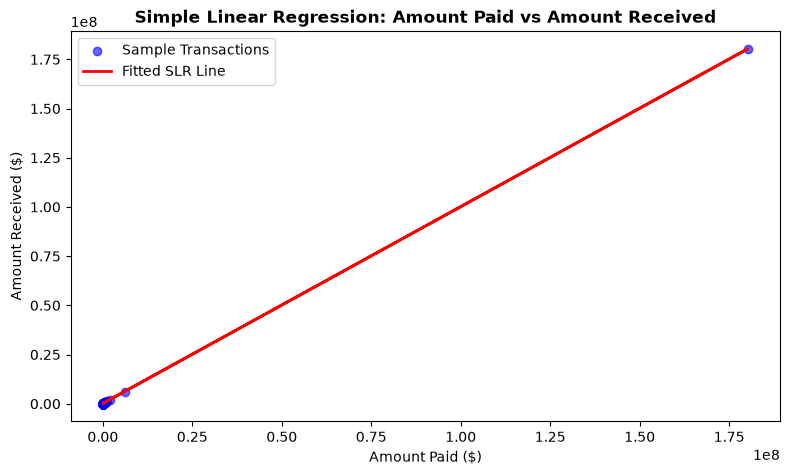

In [2]:
sample = df.sample(200, random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(sample['Amount Paid'], sample['Amount Received'], color='blue', alpha=0.6, label='Sample Transactions')
plt.plot(sample['Amount Paid'], slr_model.predict(sample[['Amount Paid']]), color='red', linewidth=2, label='Fitted SLR Line')
plt.title("Simple Linear Regression: Amount Paid vs Amount Received", fontsize=12, fontweight='bold')
plt.xlabel("Amount Paid ($)")
plt.ylabel("Amount Received ($)")
plt.legend()
plt.tight_layout()
plt.show()